# 01 · Calidad de los datos — PGCB Hourly Generation Dataset

**Objetivo de este notebook:** revisar si podemos confiar en los datos antes de analizarlos, corregir los problemas
y guardar una versión limpia.

Responde la pregunta: *¿los datos sirven para pronosticar la demanda y detectar el déficit?*

In [122]:
import sys, json
from pathlib import Path
import pandas as pd

# Ubicación del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.limpieza import cargar_crudo, limpiar, FUENTES

## 1. Cargar los datos originales
Ordenamos por fecha el archivo ya que viene en desorden.

In [123]:
crudo = cargar_crudo(RAIZ / "data/raw/PGCB_date_power_demand.xlsx")
print("Filas y columnas:", crudo.shape)
print("Desde", crudo["datetime"].min(), "hasta", crudo["datetime"].max())
crudo.head()

Filas y columnas: (92650, 15)
Desde 2015-04-19 00:00:00 hasta 2025-06-17 12:00:00


,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
0,2015-04-19 00:00:00,4821.0,4821,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
1,2015-04-19 01:00:00,3612.0,3612,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
2,2015-04-19 02:00:00,3727.0,3727,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
3,2015-04-19 03:00:00,3632.0,3632,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
4,2015-04-19 04:00:00,3641.0,3641,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN


## 2. Tipos de datos y resumen estadístico
Miramos el mínimo, la mediana y el máximo de cada columna. Un máximo muy lejos de la mediana indica un posible error.

In [124]:
crudo.dtypes

datetime                datetime64[ns]
generation_mw                  float64
demand_mw                        int64
load_shedding                    int64
gas                              int64
liquid_fuel                      int64
coal                             int64
hydro                            int64
solar                          float64
wind                           float64
india_bheramara_hvdc             int64
india_tripura                    int64
india_adani                    float64
nepal                          float64
remarks                         object
dtype: object

In [125]:
crudo.describe().T[["min", "50%", "max"]]

,min,50%,max
datetime,2015-04-19 00:00:00,2020-05-21 15:30:00,2025-06-17 12:00:00
generation_mw,73.0,8412.0,64526500.0
demand_mw,6.0,8422.0,156050.0
load_shedding,0.0,0.0,65359.0
gas,0.0,5022.0,74818.0
liquid_fuel,0.0,1535.0,29222897.0
coal,0.0,401.0,31687.0
hydro,0.0,79.0,5623.0
solar,0.0,0.0,2998.0
wind,0.0,4.0,922.0


**Hallazgo:** el máximo de `generation_mw` es 64.526.500 MW, cuando la mediana es de unos 8.400 MW.
Es un error de digitación: hay que tratar los valores atípicos.

## 3. Valores vacíos
UCI dice que el conjunto no tiene faltantes. Lo verificamos.

In [126]:
vacios = crudo.isna().sum()
vacios[vacios > 0]

solar          22133
wind           73974
india_adani    85312
nepal          87299
remarks        86257
dtype: int64

Algunas fuentes tienen miles de vacíos. ¿Son datos perdidos o plantas que todavía no existían?
Buscamos la primera fecha en que cada una tiene dato.

In [127]:
{c: str(crudo.loc[crudo[c].notna(), "datetime"].min().date()) for c in ["solar", "wind", "india_adani", "nepal"]}

{'solar': '2017-09-20',
 'wind': '2023-05-13',
 'india_adani': '2024-08-28',
 'nepal': '2024-11-14'}

**Hallazgo:** las fuentes empiezan en fechas posteriores (solar 2017, eólica 2023, Adani y Nepal 2024).
Los vacíos significan *0 MW*, no datos perdidos. `remarks` es texto y casi siempre va vacío.

## 4. Registros fuera de la hora en punto y duplicados
La serie debería tener un registro por hora. Revisamos los minutos y las fechas repetidas.

In [128]:
fuera_de_hora = crudo["datetime"].dt.minute != 0
print("Registros que no están en punto:", fuera_de_hora.sum())
print(crudo.loc[fuera_de_hora, "remarks"].value_counts())

Registros que no están en punto: 4181
remarks
Evening_Peak    620
Day_Peak          1
Name: count, dtype: int64


In [129]:
en_punto = crudo[~fuera_de_hora]
print("Fechas duplicadas:", en_punto["datetime"].duplicated().sum())
en_punto[en_punto["datetime"].duplicated(keep=False)].head(6)

Fechas duplicadas: 423


,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
76,2015-04-22 21:00:00,5811.0,5811,0,4158,1021,162,30,NaN,NaN,440,0,NaN,NaN,NaN
77,2015-04-22 21:00:00,5368.0,5368,0,4184,552,160,30,NaN,NaN,442,0,NaN,NaN,NaN
79,2015-04-23 00:00:00,5726.0,5726,0,4199,790,158,46,NaN,NaN,433,0,NaN,NaN,NaN
80,2015-04-23 00:00:00,3976.0,3976,0,3116,230,158,30,NaN,NaN,442,0,NaN,NaN,NaN
158,2015-04-27 00:00:00,5236.0,5236,0,4417,159,162,46,NaN,NaN,452,0,NaN,NaN,NaN
159,2015-04-27 00:00:00,4800.0,4800,0,3954,117,166,46,NaN,NaN,458,0,NaN,NaN,NaN


**Hallazgo:** hay registros extra del pico de la noche (17:30 y 18:30) y fechas repetidas con valores distintos.

## 5. Limpieza
La función `limpiar()` de `src/limpieza.py` hace todos los pasos:
1. Quita los registros que no están en punto.
2. Junta los duplicados con la mediana.
3. Pone 0 en las fuentes que aún no existían.
4. Marca como faltantes los atípicos: valores por debajo del 50 % o por encima del 150 % de la mediana
   de la misma hora en los 15 días vecinos (se compara con la misma hora para no confundir la noche con el pico).
5. Completa la serie hora por hora e interpola huecos de hasta 3 horas.

In [130]:
h, reporte = limpiar(crudo)
print(json.dumps(reporte, indent=1, ensure_ascii=False))

{
 "filas_originales": 92650,
 "registros_no_horarios": 4181,
 "marcas_duplicadas": 423,
 "atipicos_marcados": {
  "demand_mw": 165,
  "generation_mw": 124,
  "load_shedding": 17,
  "gas": 42,
  "liquid_fuel": 478,
  "coal": 112,
  "hydro": 68,
  "solar": 2,
  "wind": 0,
  "india_bheramara_hvdc": 19,
  "india_tripura": 43,
  "india_adani": 3,
  "nepal": 0
 },
 "horas_esperadas": 89101,
 "horas_faltantes": 1055,
 "horas_sin_demanda_tras_interpolar": 807
}


In [131]:
h.describe().T[["min", "50%", "max"]]

,min,50%,max
generation_mw,3153.0,8371.0,16603.0
demand_mw,3153.0,8383.0,17200.0
load_shedding,0.0,0.0,5443.0
gas,0.0,5022.0,9953.0
liquid_fuel,0.0,1480.0,6967.0
coal,0.0,410.0,7329.0
hydro,0.0,78.0,1875.0
solar,0.0,0.0,2901.0
wind,0.0,0.0,922.0
india_bheramara_hvdc,0.0,705.0,2503.0


## 6. Relación entre las variables
Revisamos dos cosas: que la suma de las fuentes dé la generación total, y cómo se relacionan demanda,
generación y racionamiento.

In [132]:
suma = h[FUENTES].sum(axis=1, min_count=1) / h["generation_mw"]
print("Mediana suma de fuentes / generación total:", round(suma.median(), 4))
print("% de horas dentro de ±2 %:", round(((suma - 1).abs() < 0.02).mean() * 100, 1))

Mediana suma de fuentes / generación total: 1.0007
% de horas dentro de ±2 %: 96.4


In [133]:
dif = h["demand_mw"] - h["generation_mw"]
coincide = (dif - h["load_shedding"]).abs() <= 25
print("% de horas donde demanda − generación = racionamiento:", round(coincide.mean() * 100, 1))

% de horas donde demanda − generación = racionamiento: 93.1


**Hallazgo:** la demanda es lo atendido más lo racionado. Por eso el racionamiento no puede ser
una variable de entrada del modelo de demanda: sería una fuga de información.

## 7. Guardar los datos limpios
Después de correr esta celda se versiona con DVC.

In [134]:
salida = RAIZ / "data/processed/pgcb_horario_limpio.csv"
salida.parent.mkdir(parents=True, exist_ok=True)
h.to_csv(salida)
print("Guardado:", salida, "| filas:", len(h))

Guardado: c:\Users\57313\OneDrive\Documents\GitHub\pgcb-demanda\data\processed\pgcb_horario_limpio.csv | filas: 89101


In [135]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
sns.set_theme()

##8. Análisis exploratorio
Después de correr esta celda se versiona con DVC.

In [136]:
df = pd.read_csv(salida)
df.head()

,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal
0,2015-04-19 00:00:00,4821.0,4821.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2015-04-19 01:00:00,3612.0,3612.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2015-04-19 02:00:00,3727.0,3727.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2015-04-19 03:00:00,3632.0,3632.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2015-04-19 04:00:00,3641.0,3641.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [137]:
print(df.dtypes)

datetime                 object
generation_mw           float64
demand_mw               float64
load_shedding           float64
gas                     float64
liquid_fuel             float64
coal                    float64
hydro                   float64
solar                   float64
wind                    float64
india_bheramara_hvdc    float64
india_tripura           float64
india_adani             float64
nepal                   float64
dtype: object


In [139]:
df["datetime"]=pd.to_datetime(df["datetime"])

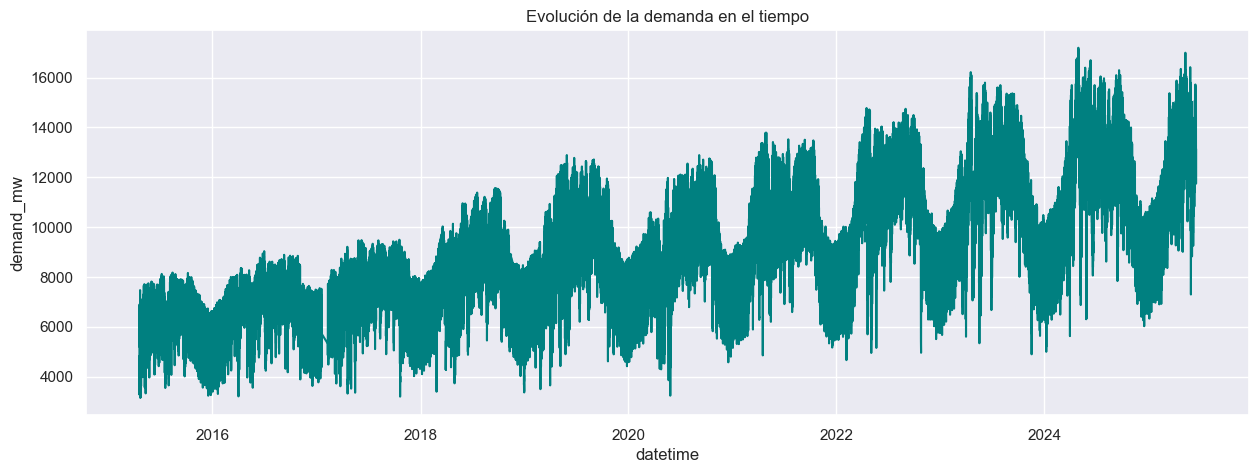

In [140]:
plt.figure(figsize=(15,5))
sns.lineplot(data=df, x="datetime", y="demand_mw", color="teal")
plt.title("Evolución de la demanda en el tiempo")
plt.show()

En nuestro gráfico podemos ver claramente varios componentes:
- Podemos ver un componente de tendencia creciente, en donde a medida que pasa el tiempo la demanda de energía en MwH es mayor.
- Podemos ver también un componente de estacionalidad, en donde parece que a mediados de año hay una demanda mayor de energía que al comienzo o al final.
- Nuestra serie también parece que ha aumentado la varianza con el tiempo, en el primer año de la base de datos la demanda en MhW osciló entre 4K - 8K MwH mientras en el último año(2025) se ubicó en el rango de 6K - 18K MwH, esto nos comienza a sugerir próximos pasos en la preparación de los datos.
A continuación, vamos a tratar los datos para poder ver estos fenómenos de una forma más clara.

In [141]:
df= df.set_index("datetime").sort_index()
serie=df["demand_mw"].asfreq("h").interpolate()

In [142]:
datos = serie.to_frame()
datos["year"] = datos.index.year
datos["month"] = datos.index.month
datos["hour"] = datos.index.hour

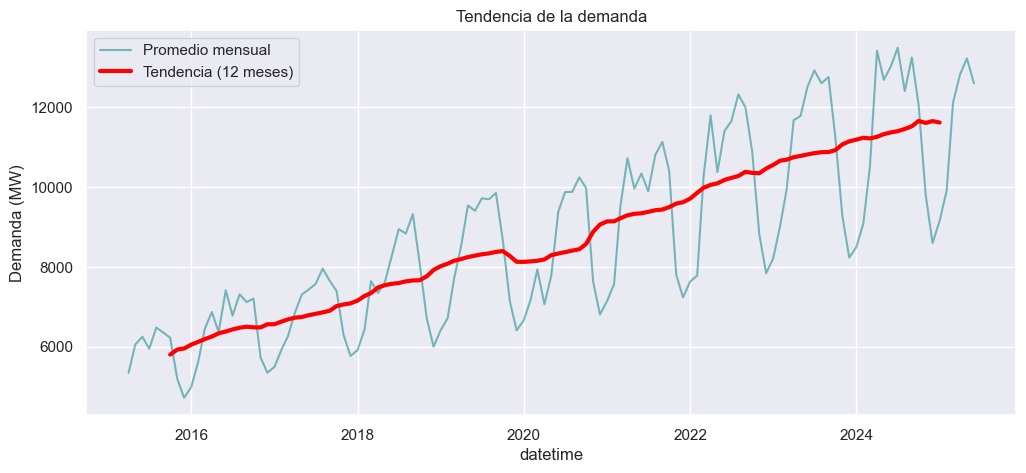

In [143]:
# Evaluamos nuestros datos ahora sacando un promedio de demanda mensual y una línea de tendencia para entender mejor cómo ha crecido la demanda de energía en el tiempo
mensual = serie.resample("MS").mean().to_frame()
mensual["tendencia"] = mensual["demand_mw"].rolling(12, center=True).mean()

plt.figure(figsize=(12, 5))
sns.lineplot(data=mensual, x=mensual.index, y="demand_mw", alpha=0.5, label="Promedio mensual", color="teal")
sns.lineplot(data=mensual, x=mensual.index, y="tendencia", linewidth=3, color="red", label="Tendencia (12 meses)")
plt.title("Tendencia de la demanda")
plt.ylabel("Demanda (MW)")
plt.show()

Confirmamos nuestra observación inicial y podemos decir que la demanda de energía tiene una tendencia creciente a lo largo del tiempo pasando de 6K MwH hasta los 12K Mwh en el espacio de 10 años de la base de datos.
Ahora ahondaremos en el comportamiento dentro de cada año, en nuestra gráfica anterior se puede ver que hay picos dentro de los años pero no es claro qué meses del año tienen el pico de demanda.

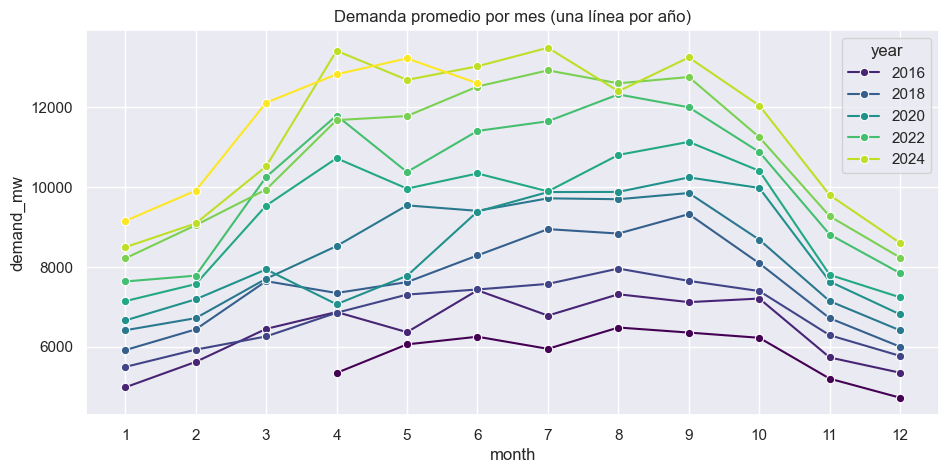

In [144]:
#Generamos una gráfica en al que se puede ver la demanda promedio de cada mes del año y la comparamos con otros años.
por_mes = datos.groupby(["year", "month"])["demand_mw"].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=por_mes, x="month", y="demand_mw", hue="year", palette="viridis", marker="o")
plt.xticks(range(1, 13))
plt.title("Demanda promedio por mes (una línea por año)")
plt.show()

En la gráfica podemos ver cierta estacionalidad entre los meses de Abril a Septiembre, intuitivamente diremos que este aumento en consumo de energía esta relacionado con factores ambientales, Bangladesh se caracteriza por tener altas temperaturas hacia la mitad del año; el consumo los demás meses es mucho más bajo.
También podemos evidenciar con esta gráfica que las primeras observaciones son en Abril de 2015 y la última está en Junio de 2025.
Finalmente veremos cómo se comporta la demanda de energía a lo largo del día.

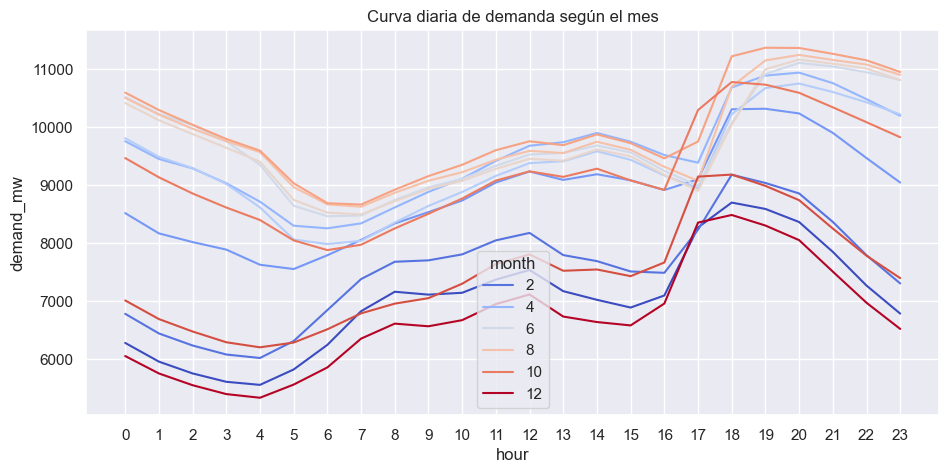

In [145]:
por_hora = datos.groupby(["month", "hour"])["demand_mw"].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=por_hora, x="hour", y="demand_mw", hue="month", palette="coolwarm")
plt.xticks(range(0, 24))
plt.title("Curva diaria de demanda según el mes")
plt.show()

Viendo el comportamiento intradía tenemos:
- Un aumento en el consumo de energía que empieza cerca de las 6 am y se mantiene con tendencia creciente hasta el medio día, esto nos habla probablemente del consumo relacionado con actividades de trabajo/estudio ya que a esta hora empieza la "actividad del día".
- Un gran consumo de energía a las 5 pm en adelante, llegando al consumo máximo a las 7 pm y manteniendose en alto consumo párcticamente hasta la media noche, acá probablemente estamos observando las horas en las que las personas llegan a sus casas después de su jornada laboral/estudiantil y el consumo residencial(ventiladores, televisores, electrodomésticos) se hace más visible.

In [146]:
df.head()

,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal
datetime,,,,,,,,,,,,,
2015-04-19 00:00:00,4821.0,4821.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2015-04-19 01:00:00,3612.0,3612.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2015-04-19 02:00:00,3727.0,3727.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2015-04-19 03:00:00,3632.0,3632.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2015-04-19 04:00:00,3641.0,3641.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
